# Random Forest — classificação da ocorrência de chuva

Objetivo: classificar se houve chuva em cada registro horário de Caruaru. **SIM=1** é a classe positiva e **NAO=0** é a negativa. Ainda não prevemos chuva futura.

Referência: **aula 08, MSc. Flávio Morais**, páginas 6–31 (métricas), 33–63 (validação e buscas) e 74–85 (Random Forest). Não implementamos os outros algoritmos citados na aula.

## 1. Importações

A floresta combina árvores treinadas com amostras bootstrap e sorteios de atributos. Usamos as mesmas bibliotecas e métricas da aula. O Pipeline mantém o preenchimento dos nulos dentro de cada ajuste.

In [2]:
import pandas as pd # permite organizar e analisar as tabelas
import matplotlib.pyplot as plt # permite desenhar os gráficos
from sklearn.compose import ColumnTransformer # aplica o tratamento às colunas escolhidas
from sklearn.ensemble import RandomForestClassifier # importa o classificador de várias árvores
from sklearn.impute import SimpleImputer # preenche valores ausentes
from sklearn.pipeline import Pipeline # reúne o tratamento e o modelo
from sklearn.metrics import ( # importa as métricas usadas na aula
    ConfusionMatrixDisplay, # desenha a matriz de confusão
    accuracy_score, # calcula a proporção total de acertos
    precision_score, # mede os acertos entre os alertas de chuva
    recall_score, # mede a detecção de chuva ou de ausência de chuva
    f1_score, # equilibra precisão e sensibilidade
    matthews_corrcoef, # considera as quatro partes da matriz de confusão
)
from sklearn.model_selection import ( # importa a validação e as duas buscas
    TimeSeriesSplit, # separa treino e validação respeitando o tempo
    cross_val_score, # calcula uma métrica em cada divisão de validação
    GridSearchCV, # testa todas as combinações da grade
    RandomizedSearchCV, # sorteia um número limitado de combinações
)


## 2. Leitura e preparação

Mantemos a base adaptada do projeto. Criamos mês e hora para representar sazonalidade. A precipitação numérica e o alvo não entram como atributos. Nenhum CSV é alterado.

In [3]:
caminho = '../dataset/INMET_NE_PE_A341_CARUARU_01-01-2025_A_31-12-2025_ADAPTADO.CSV' # indica onde está a base adaptada
# encoding permite ler os acentos do arquivo
df = pd.read_csv(caminho, encoding='iso-8859-1') # lê a base adaptada com o separador padrão de vírgula


# errors=ignore permite seguir caso a coluna não exista
df = df.drop(columns=['Unnamed: 19'], errors='ignore') # remove a coluna vazia da base


hora = df['Hora UTC'].str.extract(r'(\d{4})')[0] # extrai os quatro dígitos da hora de cada registro
df['DATA_HORA'] = pd.to_datetime( # converte a data e a hora para um único horário reconhecido pelo pandas
    # format indica a ordem ano, mês, dia, hora e minuto
    df['Data'] + ' ' + hora, format='%Y-%m-%d %H%M' # junta os textos de data e hora para fazer a conversão
)
# drop=true evita guardar o índice antigo como coluna
df = df.sort_values('DATA_HORA').reset_index(drop=True) # ordena os registros no tempo e reinicia a numeração das linhas

df['MES'] = df['DATA_HORA'].dt.month # cria o atributo numérico do mês de cada registro
df['HORA'] = df['DATA_HORA'].dt.hour # cria o atributo numérico da hora de cada registro
# classificação binária: escolhe entre duas classes, aqui chuva ou ausência de chuva
df['CHUVA_BINARIA'] = (df['CHUVA'] == 'SIM').astype(int) # transforma sim em um e os demais rótulos em zero

df[['DATA_HORA', 'CHUVA', 'CHUVA_BINARIA', 'MES', 'HORA']].head() # mostra as cinco primeiras linhas das colunas criadas


,DATA_HORA,CHUVA,CHUVA_BINARIA,MES,HORA
0,2025-01-01 00:00:00,NAO,0,1,0
1,2025-01-01 01:00:00,NAO,0,1,1
2,2025-01-01 02:00:00,NAO,0,1,2
3,2025-01-01 03:00:00,NAO,0,1,3
4,2025-01-01 04:00:00,NAO,0,1,4


## 3. Treino e teste em ordem cronológica

Os primeiros 80% dos registros formam o treino e os últimos 20% formam o teste. O teste fica fora da validação cruzada e das buscas. A proporção de chuva pode mudar entre períodos: isso faz parte da avaliação temporal.

A Decision Tree usa divisão aleatória estratificada e outro conjunto de teste. **Seus resultados não permitem comparação direta com os da floresta.**

In [4]:
colunas_remover = ['Data', 'Hora UTC', 'DATA_HORA', 'CHUVA', 'CHUVA_BINARIA'] # lista as datas e os alvos que não entrarão como atributos
# features e target: features são as entradas e target é a resposta que queremos classificar
X = df.drop(columns=colunas_remover) # mantém somente os atributos usados para classificar a chuva
y = df['CHUVA_BINARIA'] # separa o alvo numérico de ocorrência de chuva

# divisão de treino e teste: separa dados para aprender de dados reservados para avaliar
ponto_corte = int(len(df) * 0.80) # marca o fim dos primeiros oitenta por cento dos registros
X_train, X_test = X.iloc[:ponto_corte], X.iloc[ponto_corte:] # separa os atributos mais antigos para treino e os posteriores para teste
y_train, y_test = y.iloc[:ponto_corte], y.iloc[ponto_corte:] # separa as classes na mesma ordem dos atributos

print(f'Treino: {len(X_train)} registros — {df.loc[ponto_corte - 1, "DATA_HORA"]}') # mostra o tamanho do treino e o último horário desse período
print(f'Teste:  {len(X_test)} registros — de {df.loc[ponto_corte, "DATA_HORA"]} até {df.loc[len(df) - 1, "DATA_HORA"]}') # mostra o tamanho e o intervalo de horários do teste
print(f'Proporção de chuva no treino: {y_train.mean():.2%}') # mostra a proporção de registros com chuva no treino
print(f'Proporção de chuva no teste: {y_test.mean():.2%}') # mostra a proporção de registros com chuva no teste


Treino: 7008 registros — 2025-10-19 23:00:00
Teste:  1752 registros — de 2025-10-20 00:00:00 até 2025-12-31 23:00:00
Proporção de chuva no treino: 18.45%
Proporção de chuva no teste: 1.54%


## 4. Modelo inicial

Mantemos as **400 árvores** do modelo existente. A mediana e os indicadores de ausência são aprendidos somente no treino. Não normalizamos: as divisões das árvores não exigem a mesma escala dos atributos.

`balanced_subsample` dá mais peso à classe rara em cada amostra bootstrap; não remove registros. Os demais parâmetros usam os padrões da biblioteca, como `criterion='gini'`, `max_depth=None`, `max_features='sqrt'` e `bootstrap=True`.

In [5]:
colunas_numericas = X_train.select_dtypes(include='number').columns.tolist() # lista os atributos numéricos
# imputação: preenche valores ausentes com uma medida, como média ou mediana
preparacao = ColumnTransformer([ # define o tratamento das colunas numéricas
    ('numericas', SimpleImputer( # preenche as ausências antes do treinamento
        strategy='median', # usa a mediana aprendida apenas no treino
        add_indicator=True, # indica também onde faltavam valores
    ), colunas_numericas), # seleciona as colunas que serão tratadas
])
# data leakage: acontece quando dados de avaliação influenciam o preparo ou a escolha do modelo
pipeline_rf = Pipeline([ # aplica a preparação antes de treinar a floresta
    ('preparacao', preparacao), # mantém o tratamento dentro de cada ajuste
    # random forest: combina várias árvores para decidir a classe de um registro
    # bagging: combina modelos treinados de forma independente em amostras sorteadas
    # bootstrap: sorteia registros com reposição, permitindo repetições na amostra
    ('modelo', RandomForestClassifier( # cria o mesmo tipo de modelo já existente
        # hiperparâmetros: são escolhas feitas antes do treino, como profundidade e número de árvores
        n_estimators=400, # combina quatrocentas árvores
        # desbalanceamento de classes: acontece quando uma classe tem muito mais registros que a outra
        class_weight='balanced_subsample', # aumenta o peso da classe rara em cada amostra
        # random_state: fixa os sorteios para permitir repetir os resultados
        random_state=42, # permite repetir os sorteios do modelo
        n_jobs=-1, # usa os processadores disponíveis nas árvores
    )),
])
# aprendizado supervisionado: aprende com exemplos que já possuem a resposta correta
# parâmetros: são as regras e os limites que o modelo aprende durante o treino
pipeline_rf.fit(X_train, y_train) # treina o modelo inicial somente com o treino
print('Modelo inicial treinado:', len(X_train), 'registros') # confirma o tamanho usado no ajuste


Modelo inicial treinado: 7008 registros


## 5. Validação cruzada temporal — cinco folds

Usamos `TimeSeriesSplit(n_splits=5, gap=24)`: o treino cresce no tempo e cada validação vem depois, sem embaralhar. O Pipeline aprende o preenchimento novamente em cada fold. As contagens mostram que a proporção de chuva varia entre períodos.

O intervalo de 24 horas reduz a proximidade imediata, mas não garante independência. É uma adaptação do exemplo da aula à divisão cronológica deste projeto.

Escolhemos por **F1 de SIM=1**, para equilibrar alertas corretos e chuvas detectadas em uma base desbalanceada. O teste final não participa.

In [6]:
# cross-validation: avalia o modelo em diferentes partes dos dados de treinamento
cv_temporal = TimeSeriesSplit( # prepara as divisões em ordem de tempo
    n_splits=5, # faz cinco avaliações temporais
    gap=24, # separa treino e validação por vinte e quatro horas
)
resumo_folds = [] # guarda o tamanho e as classes de cada divisão
for numero, (treino, validacao) in enumerate(cv_temporal.split(X_train), start=1): # percorre os cinco períodos
    resumo_folds.append({ # registra as informações de cada fold
        'fold': numero, # identifica a divisão
        'treino': len(treino), # conta os registros usados para aprender
        'validacao': len(validacao), # conta os registros usados para validar
        'sim_treino': int(y_train.iloc[treino].sum()), # conta as chuvas no treino do fold
        'sim_validacao': int(y_train.iloc[validacao].sum()), # conta as chuvas na validação
    })
display(pd.DataFrame(resumo_folds)) # mostra as divisões sem consultar o teste
scores_inicial = cross_val_score( # avalia cópias do modelo inicial em cada fold
    pipeline_rf, X_train, y_train, # usa somente os dados de treino
    cv=cv_temporal, # respeita as cinco divisões temporais
    scoring='f1', # mede o f1 da classe sim
    n_jobs=1, # deixa o paralelismo para as árvores da floresta
    error_score='raise', # mostra um erro em vez de esconder uma falha de ajuste
)
display(pd.DataFrame({'Fold': range(1, 6), 'F1 — validação temporal': [f'{valor:.2%}' for valor in scores_inicial]})) # mostra as cinco avaliações
print(f'F1 médio — validação temporal, modelo inicial: {scores_inicial.mean():.2%}') # mostra o desempenho médio de validação
print(f'Desvio do F1 — validação temporal: {scores_inicial.std():.2%}') # mostra a variação entre períodos


,fold,treino,validacao,sim_treino,sim_validacao
0,1,1144,1168,103,105
1,2,2312,1168,208,161
2,3,3480,1168,363,392
3,4,4648,1168,751,357
4,5,5816,1168,1107,175


,Fold,F1 — validação temporal
0,1,41.25%
1,2,22.11%
2,3,50.80%
3,4,71.97%
4,5,68.51%


F1 médio — validação temporal, modelo inicial: 50.93%
Desvio do F1 — validação temporal: 18.31%


## 6. Grid Search

Grade pequena: quatro combinações × cinco folds = **20 ajustes**, mais refit. Usamos 100 árvores para limitar o custo. O prefixo `modelo__` indica os parâmetros da floresta dentro do Pipeline.

A busca é sequencial; cada floresta já trabalha em paralelo. Isso evita dois níveis de paralelismo e o problema de temporários entre processos do Windows.

In [7]:
# grid search: testa todas as combinações de hiperparâmetros definidas
param_grid = { # define uma grade pequena de hiperparâmetros
    'modelo__n_estimators': [100], # usa cem árvores em cada candidato da grade
    'modelo__max_depth': [8, None], # testa profundidade oito ou sem limite
    'modelo__min_samples_leaf': [1, 3], # testa uma ou três amostras mínimas por folha
}
grid = GridSearchCV( # cria a busca que testa as quatro combinações
    estimator=pipeline_rf, # inclui a preparação dentro da busca
    param_grid=param_grid, # fornece a grade de valores
    scoring='f1', # escolhe pelo f1 da classe sim
    cv=cv_temporal, # usa as mesmas cinco divisões temporais
    n_jobs=1, # evita combinar dois níveis de paralelismo
    refit=True, # ajusta o melhor candidato com todo o treino
    error_score='raise', # interrompe se algum ajuste falhar
)
grid.fit(X_train, y_train) # pesquisa somente dentro do treino
print('Grid Search concluído: 4 combinações e 5 divisões temporais') # identifica o fim da busca


Grid Search concluído: 4 combinações e 5 divisões temporais


## 7. Random Search

Sorteamos quatro entre 36 combinações possíveis: **20 ajustes** nos cinco folds, mais refit. Usamos listas, aceitas pelo Random Search apresentado na aula.

Os folds e o scoring são os mesmos do Grid. A melhor combinação é a melhor entre as testadas, sem garantia de ótimo global.

In [8]:
# random search: sorteia algumas combinações de hiperparâmetros para testar
param_dist = { # define as opções que poderão ser sorteadas
    'modelo__n_estimators': [100, 200], # sorteia cem ou duzentas árvores
    'modelo__max_depth': [6, 10, None], # sorteia a profundidade máxima de cada árvore
    'modelo__min_samples_leaf': [1, 3, 5], # sorteia o mínimo de registros por folha
    'modelo__max_features': ['sqrt', 'log2'], # sorteia a regra da quantidade de atributos por divisão
}
busca = RandomizedSearchCV( # cria a busca com combinações sorteadas
    estimator=pipeline_rf, # mantém o tratamento dos nulos dentro dos folds
    param_distributions=param_dist, # fornece as opções do sorteio
    n_iter=4, # testa somente quatro combinações para reduzir o tempo
    scoring='f1', # escolhe pelo f1 da classe sim
    cv=cv_temporal, # usa as cinco divisões temporais
    random_state=42, # permite repetir o sorteio das combinações
    n_jobs=1, # deixa o paralelismo para cada floresta
    refit=True, # ajusta o melhor candidato com todo o treino
    error_score='raise', # mostra qualquer falha de ajuste
)
busca.fit(X_train, y_train) # executa a busca sem usar o teste
print('Random Search concluído: 4 combinações e 5 divisões temporais') # identifica o fim da busca


Random Search concluído: 4 combinações e 5 divisões temporais


## 8. Comparação da validação e escolha dos parâmetros

A tabela abaixo usa **somente validação temporal dentro do treino**. Escolhemos a maior média de F1 entre Grid e Random; em empate, ficamos com Grid. A configuração inicial aparece como referência.

Nesta execução, as duas buscas empataram e encontraram os mesmos hiperparâmetros. “Otimizado” significa ajustado pela busca, sem promessa de melhora em qualquer conjunto.

O teste já foi consultado em versões anteriores, mas fica fora das buscas desta execução. Uma confirmação nova exigiria outro período de dados.

In [9]:
comparacao_cv = pd.DataFrame({ # reúne os resultados obtidos somente no treino
    'inicial': scores_inicial, # mostra o f1 temporal do modelo com quatrocentas árvores
    'grid': [grid.cv_results_[f'split{i}_test_score'][grid.best_index_] for i in range(5)], # mostra os folds do melhor grid
    'random': [busca.cv_results_[f'split{i}_test_score'][busca.best_index_] for i in range(5)], # mostra os folds do melhor sorteio
}, index=[f'fold {i}' for i in range(1, 6)])
display(comparacao_cv.map('{:.2%}'.format)) # permite conferir a variação entre os períodos
print('F1 médio por opção:') # identifica o resumo da validação
display(comparacao_cv.mean().map('{:.2%}'.format).to_frame('F1 médio — validação temporal')) # compara as médias sem usar o teste
melhor_busca = grid if grid.best_score_ >= busca.best_score_ else busca # escolhe a maior média de validação
nome_busca = 'grid' if melhor_busca is grid else 'random' # identifica a busca escolhida
modelo_otimizado = melhor_busca.best_estimator_ # recupera o modelo já ajustado com todo o treino
print('Busca escolhida:', nome_busca) # mostra de onde veio o modelo ajustado
resumo_buscas = [] # guarda uma linha de apresentação para cada busca
for nome, pesquisa in {'Grid Search': grid, 'Random Search': busca}.items(): # consulta as duas buscas já realizadas
    parametros = pesquisa.best_params_ # recupera os valores escolhidos na validação
    resumo_buscas.append({ # prepara uma tabela simples dos melhores candidatos
        'Busca': nome, # identifica a forma de pesquisa
        'Árvores': parametros['modelo__n_estimators'], # mostra a quantidade encontrada
        'Profundidade': parametros['modelo__max_depth'] if parametros['modelo__max_depth'] is not None else 'sem limite', # identifica o limite de profundidade
        'Mínimo por folha': parametros['modelo__min_samples_leaf'], # mostra o tamanho mínimo das folhas
        'Atributos por divisão': parametros.get('modelo__max_features', 'sqrt'), # mostra a regra de sorteio dos atributos
        'F1 médio — CV temporal': f'{pesquisa.best_score_:.2%}', # apresenta o resultado de validação
    })
display(pd.DataFrame(resumo_buscas)) # compara os melhores hiperparâmetros das buscas


,inicial,grid,random
fold 1,41.25%,56.70%,56.70%
fold 2,22.11%,58.04%,58.04%
fold 3,50.80%,68.45%,68.45%
fold 4,71.97%,71.54%,71.54%
fold 5,68.51%,65.38%,65.38%


F1 médio por opção:


,F1 médio — validação temporal
inicial,50.93%
grid,64.02%
random,64.02%


Busca escolhida: grid


,Busca,Árvores,Profundidade,Mínimo por folha,Atributos por divisão,F1 médio — CV temporal
0,Grid Search,100,sem limite,3,sqrt,64.02%
1,Random Search,100,sem limite,3,sqrt,64.02%


## 9. Comparação no teste cronológico reservado

Agora avaliamos os dois modelos no **mesmo teste**, após escolher os parâmetros. SIM=1 é positivo. Os gráficos usam a ordem **[NAO, SIM]**, formando `[[vn, fp], [fn, vp]]`.

As métricas vêm do scikit-learn: especificidade é o recall de NAO. Exibimos percentuais com duas casas e MCC com quatro; os valores internos não são arredondados. `zero_division=0` evita métricas indefinidas.

Esta tabela é de **teste**, enquanto as anteriores são de **validação cruzada**. As definições e a interpretação estão no guia rápido.

Métricas no teste cronológico — classe positiva: SIM=1


,Acurácia,Precisão SIM,Sensibilidade SIM,Especificidade,F1 SIM,MCC
Floresta inicial,98.80%,100.00%,22.22%,100.00%,36.36%,0.4686
Floresta ajustada,99.03%,85.71%,44.44%,99.88%,58.54%,0.6133


Modelo: inicial


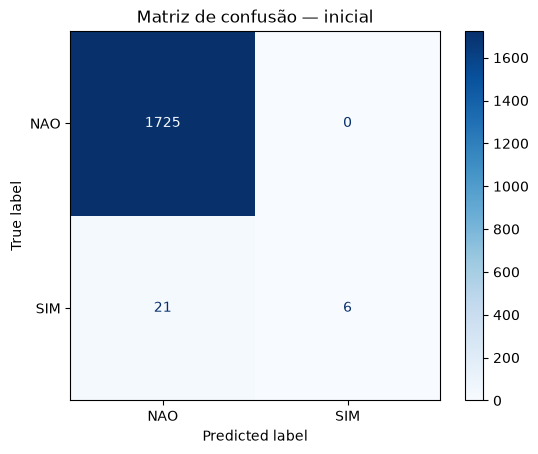

Modelo: otimizado


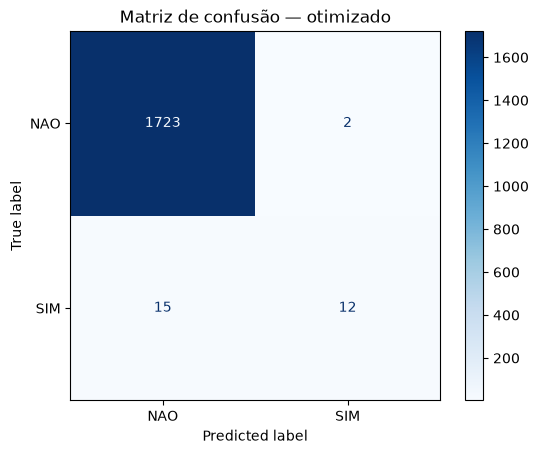

In [10]:
pred_inicial = pipeline_rf.predict(X_test) # classifica o teste com o modelo inicial
pred_otimizado = modelo_otimizado.predict(X_test) # classifica o mesmo teste com o modelo ajustado
previsoes_modelos = { # guarda as previsões dos dois modelos já escolhidos
    'inicial': pred_inicial, # identifica a floresta de quatrocentas árvores
    'otimizado': pred_otimizado, # identifica a floresta escolhida pela validação
}
resultados = {} # guarda as métricas finais de cada modelo
for nome, previsoes in previsoes_modelos.items(): # avalia cada conjunto de previsões
    resultados[nome] = { # calcula as métricas sem treinar novamente
        # acurácia: mostra a proporção total de previsões corretas
        'acuracia': accuracy_score(y_test, previsoes), # mede a proporção total de acertos
        # precisão: das vezes em que o modelo disse que choveu, quantas ele acertou
        'precisao_sim': precision_score(y_test, previsoes, pos_label=1, zero_division=0), # mede os acertos dos alertas de chuva
        # sensibilidade: das vezes em que realmente choveu, quantas o modelo identificou
        'sensibilidade_sim': recall_score(y_test, previsoes, pos_label=1, zero_division=0), # mede a proporção de chuvas detectadas
        # especificidade: das vezes em que não choveu, quantas o modelo identificou corretamente
        'especificidade': recall_score(y_test, previsoes, pos_label=0, zero_division=0), # mede a detecção das horas sem chuva
        # f1-score: mede o equilíbrio entre precisão e sensibilidade
        'f1_sim': f1_score(y_test, previsoes, pos_label=1, zero_division=0), # equilibra precisão e sensibilidade de chuva
        # mcc: considera acertos e erros das duas classes em uma medida de menos um a um
        'mcc': matthews_corrcoef(y_test, previsoes), # considera os acertos e erros das duas classes
    }
comparacao = pd.DataFrame(resultados).T # coloca os modelos nas linhas da tabela
exibicao = comparacao.copy() # preserva os valores usados nos cálculos
for coluna in comparacao.columns: # escolhe como apresentar cada métrica
    formato = '{:.4f}' if coluna == 'mcc' else '{:.2%}' # separa o mcc dos percentuais
    exibicao[coluna] = comparacao[coluna].map(formato.format) # formata apenas a visualização
exibicao = exibicao.rename(columns={'acuracia': 'Acurácia', 'precisao_sim': 'Precisão SIM', 'sensibilidade_sim': 'Sensibilidade SIM', 'especificidade': 'Especificidade', 'f1_sim': 'F1 SIM', 'mcc': 'MCC'}) # identifica as métricas
exibicao.index = ['Floresta inicial', 'Floresta ajustada'] # identifica claramente as duas versões
print('Métricas no teste cronológico — classe positiva: SIM=1') # identifica o conjunto de avaliação
display(exibicao) # mostra os resultados reais do teste
for nome, previsoes in previsoes_modelos.items(): # apresenta os detalhes de cada modelo
    print('Modelo:', nome) # identifica o resultado apresentado
    # matriz de confusão: compara classes reais nas linhas com classes previstas nas colunas
    ConfusionMatrixDisplay.from_predictions( # desenha os acertos e erros do modelo
        y_test, previsoes, # compara as classes reais com as previstas
        labels=[0, 1], # fixa a classe negativa antes da positiva
        display_labels=['NAO', 'SIM'], # escreve os nomes das classes nos eixos
        cmap='Blues', # usa tons de azul para representar as quantidades
    )
    plt.title(f'Matriz de confusão — {nome}') # identifica o modelo no título
    plt.show() # mostra a matriz de confusão


## 10. Importância dos atributos

As importâncias vêm das reduções de impureza das árvores e não provam causa e efeito. Variáveis correlacionadas podem dividir importância. Indicadores de ausência são atributos criados na preparação.

A tabela apresenta participação percentual na importância total de cada modelo.

,inicial,otimizado
"UMIDADE RELATIVA DO AR, HORARIA (%)",15.31%,16.19%
UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),10.79%,11.21%
UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),7.73%,9.58%
HORA,6.15%,6.28%
TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),4.80%,5.28%
"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",5.04%,5.11%
TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),4.82%,4.62%
RADIACAO GLOBAL (Kj/m²),5.11%,4.55%
"VENTO, DIREÇÃO HORARIA (gr) (° (gr))",4.79%,4.34%
TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),3.91%,4.00%


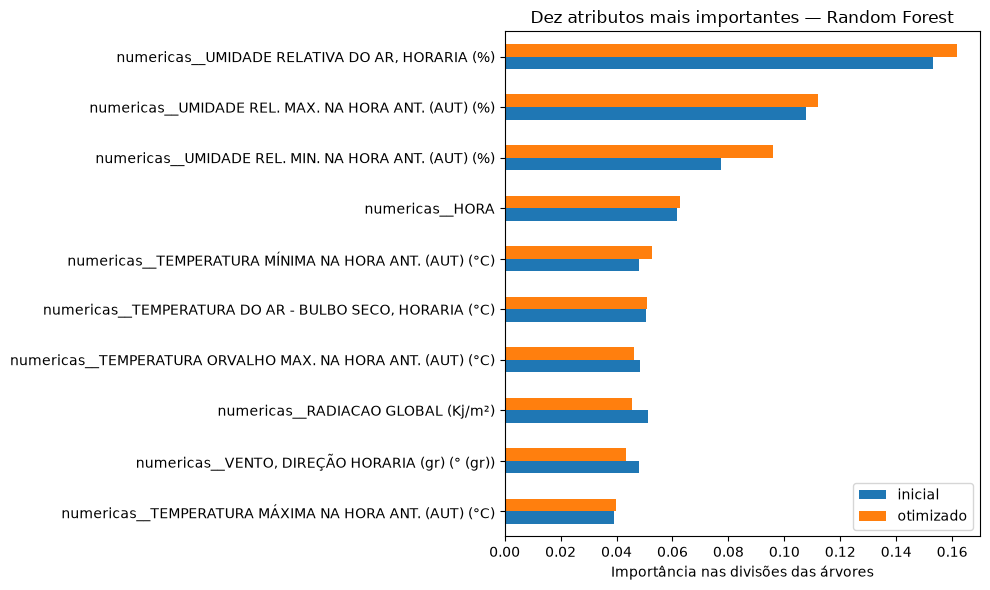

In [11]:
# importância dos atributos: mostra a contribuição de cada variável nas divisões das árvores, sem provar causa
importancias = pd.DataFrame({ # reúne as importâncias dos dois modelos
    nome: pd.Series( # associa cada importância ao nome da variável tratada
        modelo.named_steps['modelo'].feature_importances_, # obtém a contribuição nas divisões das árvores
        index=modelo.named_steps['preparacao'].get_feature_names_out(), # inclui os nomes dos indicadores de ausência
    )
    for nome, modelo in {'inicial': pipeline_rf, 'otimizado': modelo_otimizado}.items() # consulta cada modelo já treinado
}).sort_values('otimizado', ascending=False) # ordena pela importância na floresta ajustada
tabela_importancias = importancias.head(10).copy() # seleciona as dez maiores importâncias
tabela_importancias.index = tabela_importancias.index.str.replace('numericas__', '', regex=False) # simplifica os nomes exibidos
display(tabela_importancias.map('{:.2%}'.format)) # mostra as dez variáveis mais importantes no modelo ajustado
importancias.head(10).sort_values('otimizado').plot.barh(figsize=(10, 6)) # compara as importâncias com barras horizontais
plt.xlabel('Importância nas divisões das árvores') # identifica o significado do eixo horizontal
plt.title('Dez atributos mais importantes — Random Forest') # define o título do gráfico
plt.tight_layout() # ajusta o espaço para os nomes dos atributos
plt.show() # mostra o gráfico de importâncias


## Como explicar o resultado

“Escolhemos hiperparâmetros pelo F1 de chuva em cinco validações temporais, somente dentro do treino. Depois comparamos a floresta inicial e a ajustada no teste reservado, analisando também especificidade e MCC.”

**Pronto:** treinamento, matrizes, métricas automáticas, cinco folds, duas buscas, comparação e importância dos atributos.

**Pendências:** ampliar os dados, revisar os quatro rótulos associados a precipitações ausentes e avaliar outros períodos. Não prevemos chuva futura nem comparamos diretamente estes resultados aos da árvore, que usa outro teste.